# Notebook 02 — EDA: Rule-Based Model
**Question:** Which filters actually help, and do they produce a stable edge?

**Hypothesis (pre-registered):**  
The rule-based file (5-year, filtered signals) should show higher expectancy and profit factor vs. the unfiltered base. At least one filter should provide a statistically meaningful improvement; filters are expected to interact (AND combinations beat any single filter). Some filter combos may reduce trade count below the 30/month target.

**Threats to validity:** multiple comparisons (track attempt count), single instrument, threshold data-snooping.

In [1]:
import json, warnings, itertools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
%matplotlib inline

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ── HYPOTHESIS COUNTER (tracks how many variants are tested) ────────────────
HYPOTHESIS_COUNT = 0

rb = pd.read_csv('../DATA/rulebased_5yr_processed.csv', parse_dates=['open_time','close_time'])
rb = rb.sort_values('open_time').reset_index(drop=True)

# Also load base for comparison
base = pd.read_csv('../DATA/base_ml_4yr_processed.csv', parse_dates=['open_time','close_time'])
base = base.sort_values('open_time').reset_index(drop=True)

# Use only the common date window
start = max(rb['open_time'].min(), base['open_time'].min())
end   = min(rb['open_time'].max(), base['open_time'].max())
rb_w   = rb[(rb['open_time'] >= start) & (rb['open_time'] <= end)].copy()
base_w = base[(base['open_time'] >= start) & (base['open_time'] <= end)].copy()

print(f'Common window: {start.date()} → {end.date()}')
print(f'Base trades : {len(base_w):,}')
print(f'Rule-based  : {len(rb_w):,}')

Common window: 2022-01-13 → 2026-09-22
Base trades : 3,032
Rule-based  : 980


## 1. Base vs Rule-Based — Headline Comparison

In [2]:
def compute_metrics(df, label=''):
    n       = len(df)
    if n == 0:
        return dict(label=label, n=0, wr=np.nan, exp_r=np.nan, pf=np.nan, mdd=np.nan)
    wr      = (df['result_R'] > 0).mean()
    exp_r   = df['result_R'].mean()
    winners = df.loc[df['result_R'] > 0, 'result_R'].sum()
    losers  = df.loc[df['result_R'] < 0, 'result_R'].sum()
    pf      = winners / abs(losers) if losers != 0 else np.nan
    eq      = df['result_R'].cumsum()
    mdd     = (eq - eq.cummax()).min()
    months  = df.set_index('open_time').resample('ME').size().mean()
    return dict(label=label, n=n, wr=round(wr,4), exp_r=round(exp_r,4),
                pf=round(pf,3), mdd=round(mdd,3), avg_trades_month=round(months,1))

m_base = compute_metrics(base_w, 'Base (unfiltered)')
m_rb   = compute_metrics(rb_w,   'Rule-Based')

summary = pd.DataFrame([m_base, m_rb]).set_index('label')
display(summary)

,n,wr,exp_r,pf,mdd,avg_trades_month
label,,,,,,
Base (unfiltered),3032,0.3608,0.0754,1.116,-92.793,53.2
Rule-Based,980,0.3704,0.1927,1.305,-47.961,17.2


## 2. Rule Ablation — Filters Available in Data

In [3]:
# We define proxy rules from feature columns
# (These replicate likely rule-based criteria inferred from the feature set)

RULES = {
    'ATR_High'       : lambda df: df['atr_h1_pctile'] >= 30,
    'Trend_Aligned'  : lambda df: df['align_ema50_h1'] == 1,
    'H4_Trend_Align' : lambda df: df['align_ema50_h4'] == 1,
    'Low_SL_ATR'     : lambda df: df['sl_to_atr_h1'] <= 2.0,
    'Far_EMA50_H1'   : lambda df: df['dist_ema50_h1_atr'] >= 1.0,
    'Session_Active' : lambda df: df['open_hour'].between(7, 17),
    'No_Opp_Zone'    : lambda df: df['dist_opp_zone_R'].isna() | (df['dist_opp_zone_R'] >= 2.0),
    'ADR_InRange'    : lambda df: df['day_range_to_adr'] <= 0.7,
    'EC_Momentum'    : lambda df: df['ec_tickvol_ratio'] >= 1.0,
    'Low_Spread'     : lambda df: df['spread_pips'] <= 25,
}

ablation_results = []
HYPOTHESIS_COUNT += len(RULES)

for rule_name, rule_fn in RULES.items():
    try:
        mask = rule_fn(rb_w)
        sub  = rb_w[mask]
        m    = compute_metrics(sub, rule_name)
        m['pct_trades'] = round(len(sub)/len(rb_w)*100, 1)
        ablation_results.append(m)
    except Exception as e:
        ablation_results.append(dict(label=rule_name, error=str(e)))

ablation_df = pd.DataFrame(ablation_results).set_index('label').sort_values('exp_r', ascending=False)
print(f'Variants tested so far: {HYPOTHESIS_COUNT}')
display(ablation_df[['n','pct_trades','wr','exp_r','pf','mdd','avg_trades_month']])

Variants tested so far: 10


,n,pct_trades,wr,exp_r,pf,mdd,avg_trades_month
label,,,,,,,
Session_Active,442,45.1,0.3824,0.2269,1.365,-25.280,7.8
ATR_High,781,79.7,0.3803,0.2217,1.356,-33.131,13.7
H4_Trend_Align,821,83.8,0.3764,0.2120,1.338,-39.744,14.4
Low_Spread,899,91.7,0.3760,0.2115,1.338,-47.961,16.1
No_Opp_Zone,980,100.0,0.3704,0.1927,1.305,-47.961,17.2
Low_SL_ATR,932,95.1,0.3670,0.1795,1.282,-45.960,16.4
Far_EMA50_H1,556,56.7,0.3669,0.1778,1.279,-20.930,9.8
ADR_InRange,495,50.5,0.3616,0.1661,1.259,-35.521,8.7
Trend_Aligned,706,72.0,0.3612,0.1621,1.252,-29.901,12.4


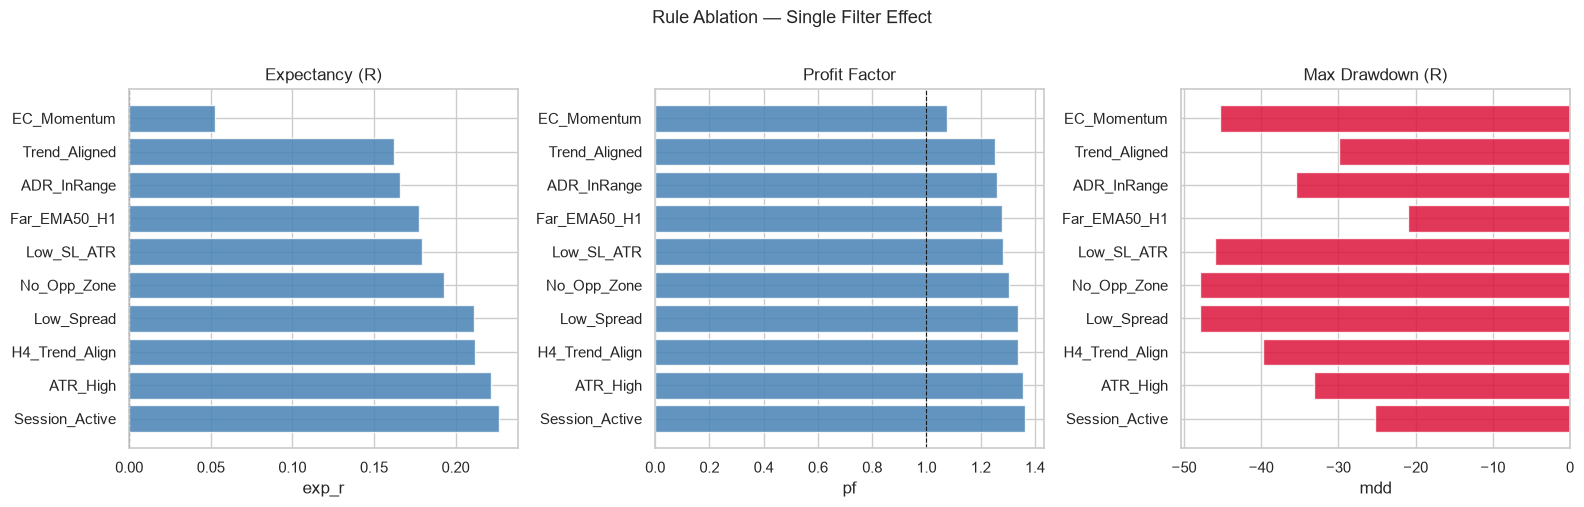

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics_to_plot = ['exp_r','pf','mdd']
titles = ['Expectancy (R)', 'Profit Factor', 'Max Drawdown (R)']
cmap_fn = [lambda v: 'steelblue' if v > 0 else 'crimson',
           lambda v: 'steelblue' if v > 1 else 'crimson',
           lambda v: 'crimson' if v < -5 else 'steelblue']

for ax, met, ttl, cfn in zip(axes, metrics_to_plot, titles, cmap_fn):
    vals = ablation_df[met].dropna()
    colors = [cfn(v) for v in vals.values]
    ax.barh(vals.index, vals.values, color=colors, alpha=0.85)
    ax.axvline(0 if met in ['exp_r','mdd'] else 1, color='k', lw=0.8, ls='--')
    ax.set_title(ttl); ax.set_xlabel(met)

plt.suptitle('Rule Ablation — Single Filter Effect', y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig('../DATA/02_rule_ablation.png', dpi=120)
plt.show()

## 3. Rule Combinations & Overlap

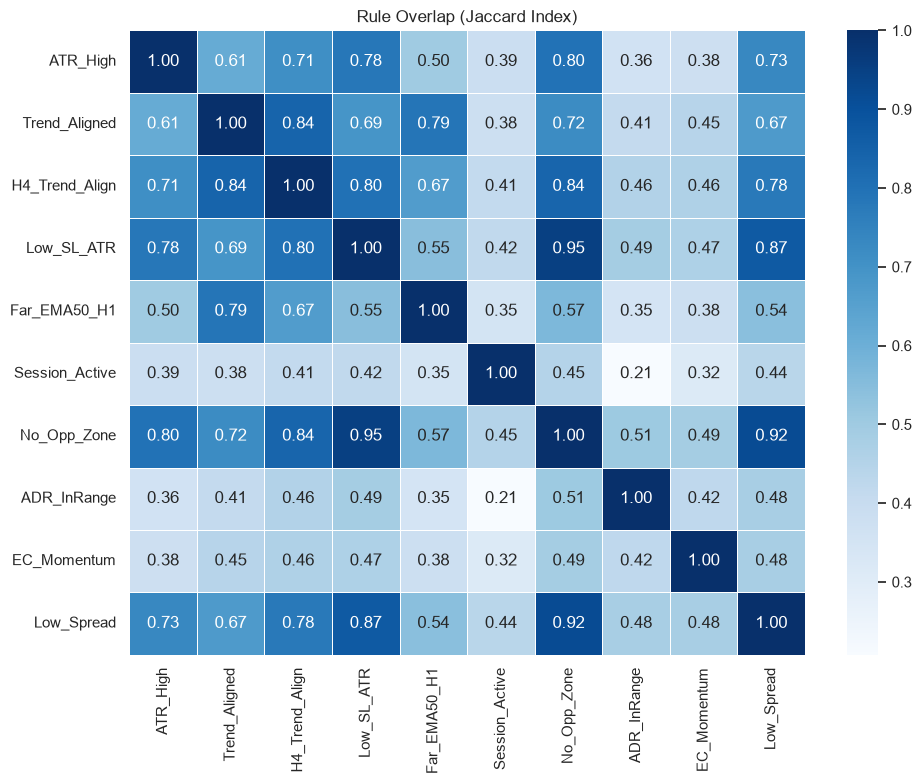

In [5]:
# Build boolean matrix for rule membership
rule_flags = pd.DataFrame(index=rb_w.index)
for rn, rfn in RULES.items():
    try:
        rule_flags[rn] = rfn(rb_w).values
    except:
        rule_flags[rn] = False

# Overlap heatmap (Jaccard)
jaccard = pd.DataFrame(index=RULES.keys(), columns=RULES.keys(), dtype=float)
for r1 in RULES:
    for r2 in RULES:
        both = (rule_flags[r1] & rule_flags[r2]).sum()
        either = (rule_flags[r1] | rule_flags[r2]).sum()
        jaccard.loc[r1, r2] = both / either if either > 0 else 0

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(jaccard.astype(float), annot=True, fmt='.2f', cmap='Blues',
            linewidths=0.5, ax=ax)
ax.set_title('Rule Overlap (Jaccard Index)')
plt.tight_layout()
plt.savefig('../DATA/02_rule_overlap.png', dpi=120)
plt.show()

In [6]:
# Top pairwise combinations
top_rules = ablation_df.head(5).index.tolist()
combo_results = []
HYPOTHESIS_COUNT += len(list(itertools.combinations(top_rules, 2)))

for r1, r2 in itertools.combinations(top_rules, 2):
    try:
        mask = RULES[r1](rb_w) & RULES[r2](rb_w)
        sub  = rb_w[mask]
        m    = compute_metrics(sub, f'{r1} AND {r2}')
        m['pct_trades'] = round(len(sub)/len(rb_w)*100, 1)
        combo_results.append(m)
    except:
        pass

combo_df = pd.DataFrame(combo_results).set_index('label').sort_values('exp_r', ascending=False)
print(f'Total variants tested: {HYPOTHESIS_COUNT}  (corrected α = {0.05/HYPOTHESIS_COUNT:.4f})')
display(combo_df[['n','pct_trades','wr','exp_r','pf','mdd','avg_trades_month']])

Total variants tested: 20  (corrected α = 0.0025)


,n,pct_trades,wr,exp_r,pf,mdd,avg_trades_month
label,,,,,,,
Session_Active AND Low_Spread,409,41.7,0.3961,0.2702,1.446,-23.268,7.3
H4_Trend_Align AND Low_Spread,753,76.8,0.3851,0.2409,1.390,-39.744,13.4
Session_Active AND ATR_High,341,34.8,0.3871,0.2397,1.389,-23.254,6.0
ATR_High AND Low_Spread,710,72.4,0.3831,0.2311,1.373,-33.131,12.7
Session_Active AND No_Opp_Zone,442,45.1,0.3824,0.2269,1.365,-25.280,7.8
ATR_High AND No_Opp_Zone,781,79.7,0.3803,0.2217,1.356,-33.131,13.7
ATR_High AND H4_Trend_Align,666,68.0,0.3784,0.2150,1.344,-32.921,11.7
H4_Trend_Align AND No_Opp_Zone,821,83.8,0.3764,0.2120,1.338,-39.744,14.4
Low_Spread AND No_Opp_Zone,899,91.7,0.3760,0.2115,1.338,-47.961,16.1


## 4. Threshold Sensitivity — Heatmaps

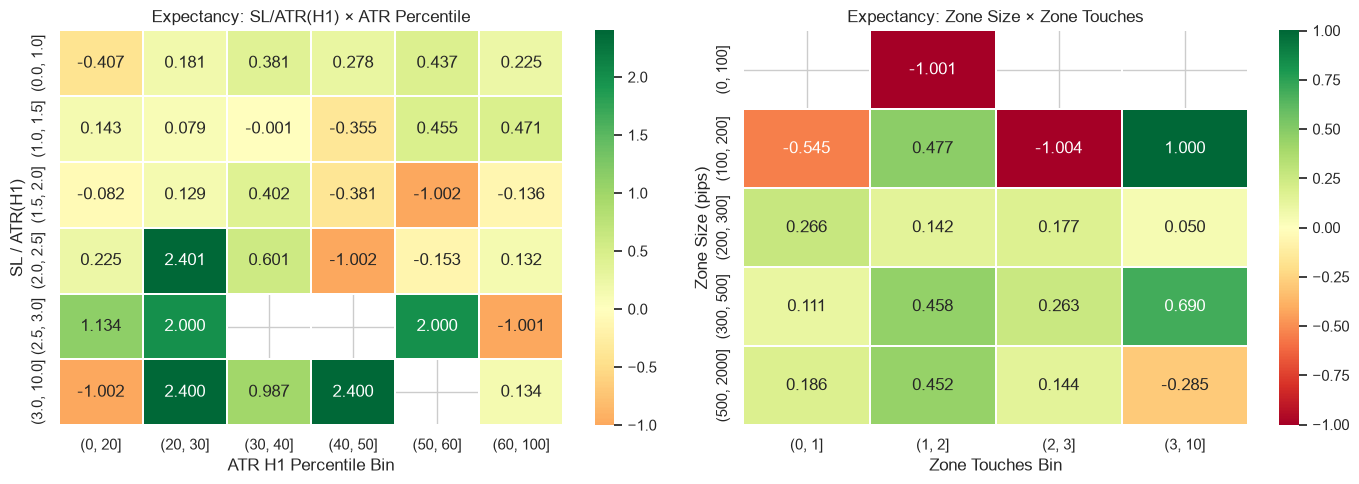

In [7]:
# Heatmap: sl_to_atr_h1 × atr_h1_pctile → expectancy
atr_pctile_bins = [0, 20, 30, 40, 50, 60, 100]
sl_atr_bins     = [0, 1.0, 1.5, 2.0, 2.5, 3.0, 10.0]

rb_w['atr_pctile_bin'] = pd.cut(rb_w['atr_h1_pctile'], bins=atr_pctile_bins)
rb_w['sl_atr_bin']     = pd.cut(rb_w['sl_to_atr_h1'],  bins=sl_atr_bins)

pivot = rb_w.pivot_table(values='result_R', index='sl_atr_bin',
                          columns='atr_pctile_bin', aggfunc='mean')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(pivot, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
            linewidths=0.3, ax=axes[0])
axes[0].set_title('Expectancy: SL/ATR(H1) × ATR Percentile')
axes[0].set_xlabel('ATR H1 Percentile Bin')
axes[0].set_ylabel('SL / ATR(H1)')

# Heatmap: zone_size_pips × zone_touches → expectancy
zone_sz_bins  = [0, 100, 200, 300, 500, 2000]
zone_tch_bins = [0, 1, 2, 3, 10]

rb_w['zone_sz_bin']  = pd.cut(rb_w['zone_size_pips'], bins=zone_sz_bins)
rb_w['zone_tch_bin'] = pd.cut(rb_w['zone_touches'],   bins=zone_tch_bins)

pivot2 = rb_w.pivot_table(values='result_R', index='zone_sz_bin',
                           columns='zone_tch_bin', aggfunc='mean')
sns.heatmap(pivot2, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
            linewidths=0.3, ax=axes[1])
axes[1].set_title('Expectancy: Zone Size × Zone Touches')
axes[1].set_xlabel('Zone Touches Bin')
axes[1].set_ylabel('Zone Size (pips)')

plt.tight_layout()
plt.savefig('../DATA/02_threshold_heatmaps.png', dpi=120)
plt.show()

## 5. Frequency vs Quality — Trades/Month vs Expectancy

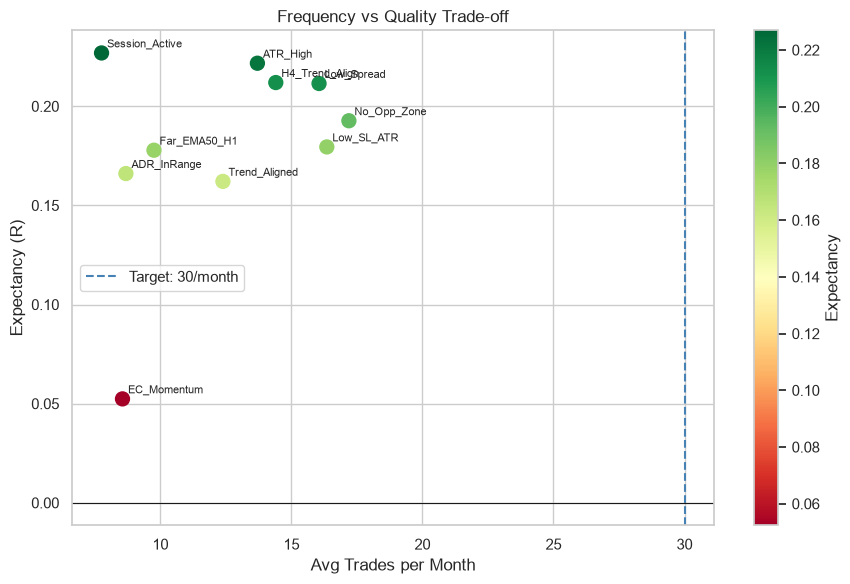

In [8]:
TARGET_TRADES_MONTH = 30

freq_quality = []
for rule_name, rule_fn in RULES.items():
    try:
        mask = rule_fn(rb_w)
        sub  = rb_w[mask]
        if len(sub) < 10:
            continue
        months = sub.set_index('open_time').resample('ME').size()
        freq_quality.append(dict(
            rule=rule_name,
            trades_per_month=months.mean(),
            exp_r=sub['result_R'].mean()
        ))
    except:
        pass

fq_df = pd.DataFrame(freq_quality)

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(fq_df['trades_per_month'], fq_df['exp_r'],
                c=fq_df['exp_r'], cmap='RdYlGn', s=100, zorder=3)
for _, row in fq_df.iterrows():
    ax.annotate(row['rule'], (row['trades_per_month'], row['exp_r']),
                fontsize=8, xytext=(4,4), textcoords='offset points')
ax.axvline(TARGET_TRADES_MONTH, color='steelblue', ls='--', lw=1.5,
           label=f'Target: {TARGET_TRADES_MONTH}/month')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('Avg Trades per Month'); ax.set_ylabel('Expectancy (R)')
ax.set_title('Frequency vs Quality Trade-off')
ax.legend()
plt.colorbar(sc, ax=ax, label='Expectancy')
plt.tight_layout()
plt.savefig('../DATA/02_frequency_quality.png', dpi=120)
plt.show()

## 6. Honest Multiple-Comparison Count

In [9]:
print(f'Total filter variants tested in this notebook : {HYPOTHESIS_COUNT}')
print(f'Bonferroni-corrected α (0.05)                 : {0.05/HYPOTHESIS_COUNT:.5f}')
print()
print('Recommendation: treat any finding with p < 0.001 as potentially spurious')
print('without out-of-sample confirmation in the holdout or 5-year file.')

Total filter variants tested in this notebook : 20
Bonferroni-corrected α (0.05)                 : 0.00250

Recommendation: treat any finding with p < 0.001 as potentially spurious
without out-of-sample confirmation in the holdout or 5-year file.


## 7. Holdout Evaluation (Rule-Based)

Rule-Based — Train+Val:


,label,n,wr,exp_r,pf,mdd,avg_trades_month
0,Train+Val,789,0.3714,0.1984,1.314,-47.961,16.8



Rule-Based — Holdout:


,label,n,wr,exp_r,pf,mdd,avg_trades_month
0,Holdout,191,0.3665,0.169,1.265,-19.062,19.1


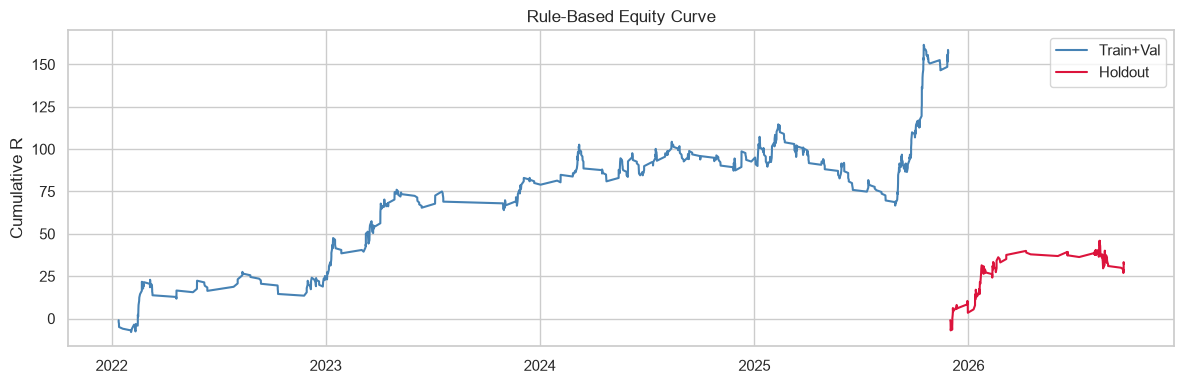

In [10]:
rb_ho   = rb[rb['split'] == 'holdout'].copy()
rb_tv   = rb[rb['split'].isin(['train','val'])].copy()

print('Rule-Based — Train+Val:')
display(pd.DataFrame([compute_metrics(rb_tv, 'Train+Val')]))
print('\nRule-Based — Holdout:')
display(pd.DataFrame([compute_metrics(rb_ho, 'Holdout')]))

fig, ax = plt.subplots(figsize=(12, 4))
for lbl, dset, col in [('Train+Val', rb_tv, 'steelblue'), ('Holdout', rb_ho, 'crimson')]:
    eq = dset['result_R'].cumsum().reset_index(drop=True)
    ax.plot(dset['open_time'].values, eq.values, lw=1.5, color=col, label=lbl)
ax.set_title('Rule-Based Equity Curve'); ax.set_ylabel('Cumulative R')
ax.legend()
plt.tight_layout()
plt.savefig('../DATA/02_rulebased_equity.png', dpi=120)
plt.show()